# C3 live demo: screenshot + UI layout (Rico screens)

Each Rico screen comes with its **UI layout**: every element's type, id, text and position. Six held-out test screens are run two ways:

| | Adapter | How the layout is used |
|---|---|---|
| **Part A** | `c3_v3_vision_1ep` (the app's default) | Decides from the screenshot; the layout names the real element under each finding. |
| **Part B** | `c3_v3_fusion_1ep` | The layout is read by the model as text in its prompt. |

The screens were fixed before running: the first test screen of each defect type, plus the first two clean ones.

**Read it honestly:** on the full test set the vision adapter is stronger (AUC 0.814 vs 0.753). The four defects here were inserted into clean screens, and their layout describes the screen *before* the defect, so it cannot reveal the defect, only where elements are.

**Green** = true region. **Red** = vision adapter. **Orange** = fusion adapter. **Thin blue** = layout elements.

Run top to bottom (about 30-40 s per model load). Close the HEART app and other notebooks holding the model first (4 GB GPU).

In [1]:
import sys, json, gc, time
from pathlib import Path
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'demo_inputs' / 'with_layout').exists())
sys.path.insert(0, str(C3.parent))
import vision_oracle.services.oracle_service as svc_mod   # must be imported first (path guard)
from local_vision_oracle.hierarchy_text import parse_elements, hierarchy_text, resolve_element, element_reference
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

DIR = C3 / 'demo_inputs' / 'with_layout'
SCREENS = json.loads((DIR / 'screens.json').read_text(encoding='utf-8'))

def rect(ax, box, w, h, color, lw=3, ls='-', alpha=1.0):
    if box:
        y1, x1, y2, x2 = box
        ax.add_patch(Rectangle((x1 * w / 1000, y1 * h / 1000), (x2 - x1) * w / 1000, (y2 - y1) * h / 1000, fill=False, ec=color, lw=lw, ls=ls, alpha=alpha))

def to_1000(xyxy, w, h):
    x1, y1, x2, y2 = xyxy
    return [round(y1 / h * 1000), round(x1 / w * 1000), round(y2 / h * 1000), round(x2 / w * 1000)]

def iou(a, b):
    if not a or not b: return 0.0
    y1, x1, y2, x2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, y2 - y1) * max(0, x2 - x1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union else 0.0

for s in SCREENS:
    print(f"{s['image']:<26} expected {s['expected']:<18} layout elements {len(parse_elements(DIR / s['layout']))}")

10017_v3_overlap.jpg       expected component_overlap  layout elements 17
10029_v3_truncation.jpg    expected text_truncation    layout elements 17
10422_v3_missing.jpg       expected missing_component  layout elements 17
10167_v3_null.jpg          expected data_binding_null  layout elements 8
10036.jpg                  expected none               layout elements 23
10182.jpg                  expected none               layout elements 35


## What the model is given: one screen and its UI hierarchy
Left: every layout element drawn on the screenshot. Right: the exact text the fusion adapter reads (up to 20 elements, the same format used in training).

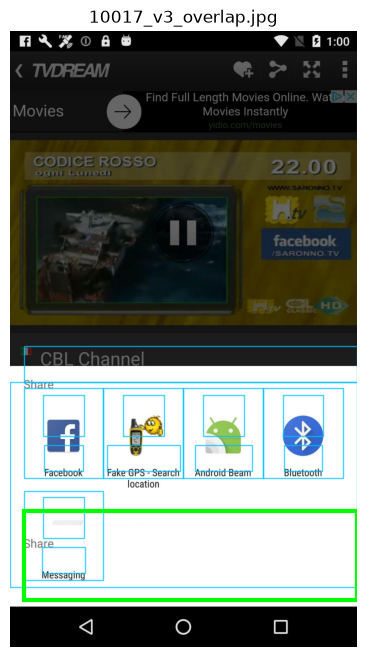

TextView#title "Share" [511,39,570,1000]
ListView#resolver_list [570,0,902,1000] click scroll
LinearLayout [580,39,725,269] click
LinearLayout [580,269,725,500] click
LinearLayout [580,500,725,731] click
LinearLayout [580,731,725,961] click
ImageView#icon [591,96,657,212]
ImageView#icon [591,326,657,443]
ImageView#icon [591,557,657,674]
ImageView#icon [591,788,657,904]
TextView#text1 "Facebook" [672,99,714,210]
TextView#text1 "Fake GPS - Search location" [672,279,714,490]
TextView#text1 "Android Beam" [672,533,714,697]
TextView#text1 "Bluetooth" [672,790,714,901]
LinearLayout [746,39,891,269] click
ImageView#icon [757,96,823,212]
TextView#text1 "Messaging" [838,91,880,217]


In [2]:
s = SCREENS[0]
img = Image.open(DIR / s['image']).convert('RGB'); W, H = img.size
fig, ax = plt.subplots(figsize=(4.5, 8)); ax.imshow(img); ax.axis('off')
for e in parse_elements(DIR / s['layout']): rect(ax, e.bounds, W, H, 'deepskyblue', lw=1, alpha=0.7)
rect(ax, s['gold_box'], W, H, 'lime'); ax.set_title(s['image']); plt.show()
print(hierarchy_text(DIR / s['layout']))

## Part A: the app's default adapter, with the layout file attached
This is exactly what the HEART app's *Inspect screenshot* button does when you add a layout file.

In [3]:
service = svc_mod.get_oracle_service()
A = {}
for s in SCREENS:
    layout_raw = (DIR / s['layout']).read_text(encoding='utf-8')
    t = time.perf_counter()
    v = service.evaluate(image_input=str(DIR / s['image']), raw_hierarchy=layout_raw, session_id='layout_demo', enable_sahi=False)['verdict_v2']
    f = v['findings'][0] if v['findings'] else {}
    with Image.open(DIR / s['image']) as im: W, H = im.size
    A[s['image']] = dict(decision=getattr(v['decision'], 'value', v['decision']), type=f.get('type', 'none'),
                         score=v['metadata'].get('defect_probability'), element=f.get('element_ref'),
                         box=to_1000(f['bbox_xyxy'], W, H) if f.get('bbox_xyxy') else None, secs=time.perf_counter() - t)
    r = A[s['image']]
    print(f"{s['image']:<26} expected {s['expected']:<18} -> {r['type']:<18} score {r['score']:.2f}  element {r['element'] or '-'}  ({r['secs']:.1f} s)")

C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:00<09:55,  1.22it/s]

Loading weights:   0%|          | 3/729 [00:00<03:08,  3.86it/s]

Loading weights:   1%|          | 4/729 [00:01<02:34,  4.69it/s]

...

10029_v3_truncation.jpg    expected text_truncation    -> none               score 0.29  element -  (1.0 s)


10422_v3_missing.jpg       expected missing_component  -> missing_component  score 0.48  element com.bookmark.money:id/walkthrough_text  (5.0 s)


10167_v3_null.jpg          expected data_binding_null  -> data_binding_null  score 1.00  element com.android.browser:id/url  (4.9 s)


10036.jpg                  expected none               -> none               score 0.21  element -  (0.8 s)


10182.jpg                  expected none               -> text_truncation    score 0.41  element -  (5.0 s)


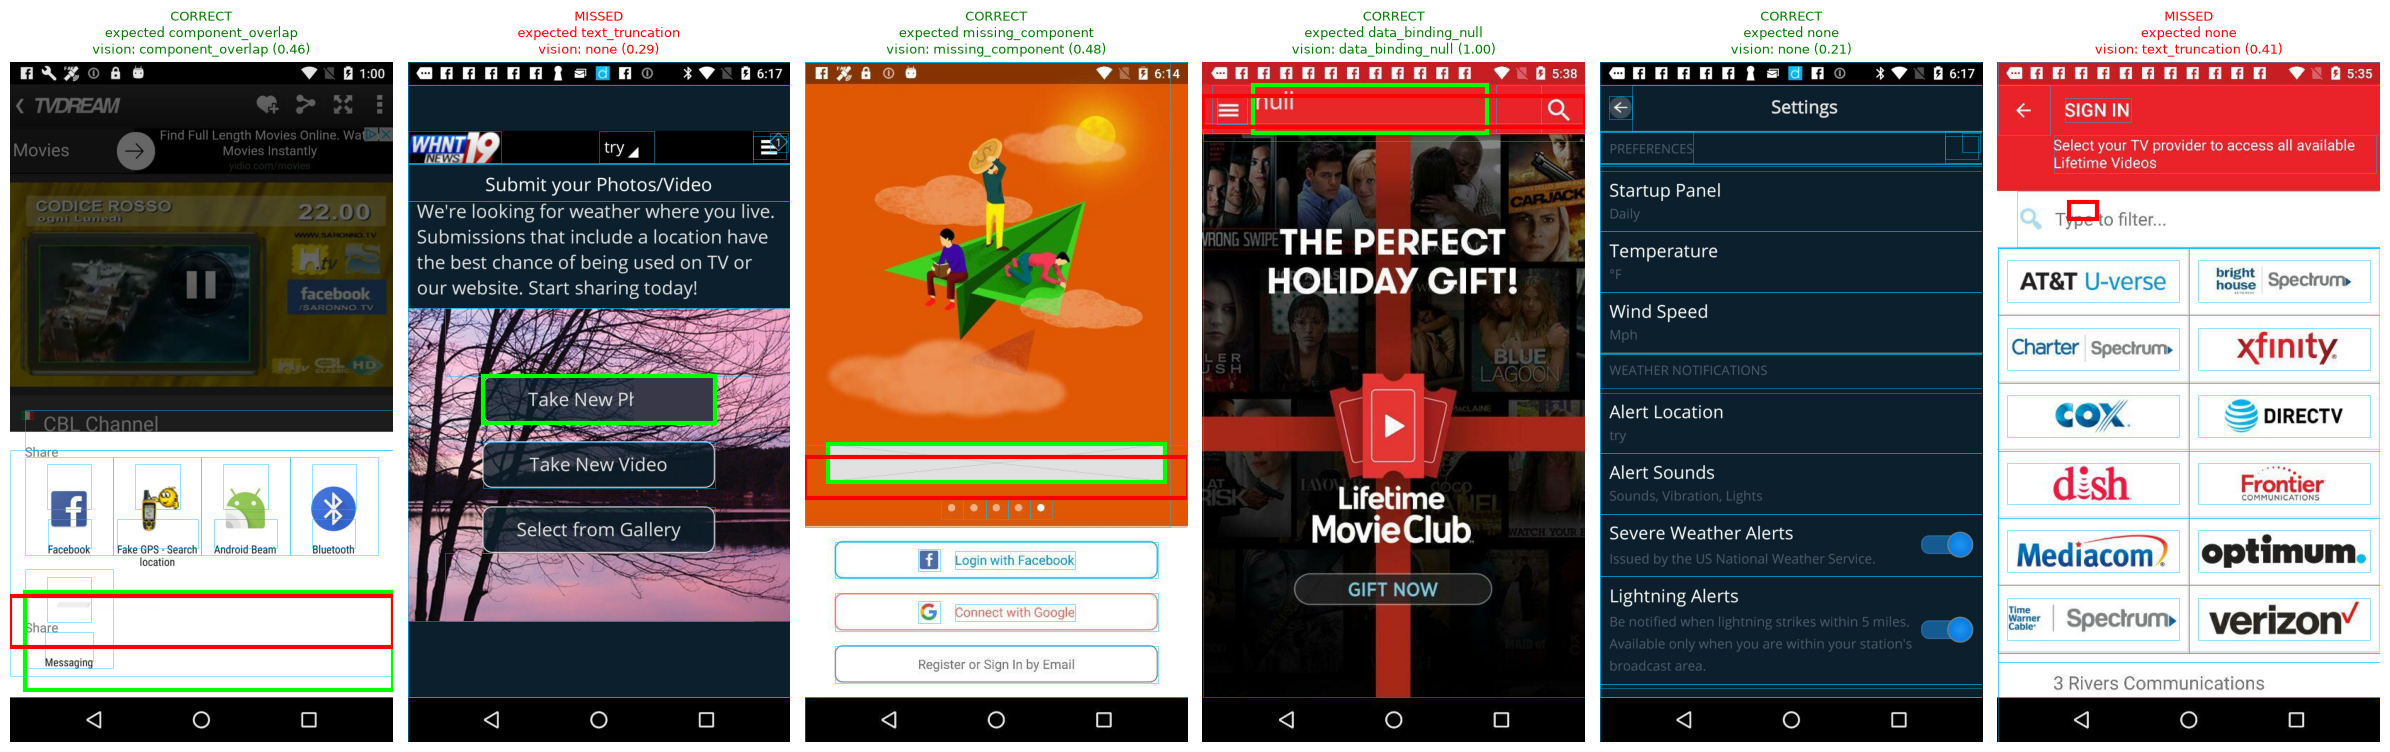

In [4]:
fig, axes = plt.subplots(1, len(SCREENS), figsize=(4 * len(SCREENS), 8))
for ax, s in zip(axes, SCREENS):
    img = Image.open(DIR / s['image']).convert('RGB'); W, H = img.size; ax.imshow(img); ax.axis('off')
    for e in parse_elements(DIR / s['layout']): rect(ax, e.bounds, W, H, 'deepskyblue', lw=0.6, alpha=0.5)
    r = A[s['image']]; rect(ax, s['gold_box'], W, H, 'lime'); rect(ax, r['box'], W, H, 'red')
    ok = r['type'] == s['expected']
    ax.set_title(f"{'CORRECT' if ok else 'MISSED'}\nexpected {s['expected']}\nvision: {r['type']} ({r['score']:.2f})", color='green' if ok else 'red', fontsize=9)
plt.tight_layout(); plt.show()

### Free the GPU before loading the second adapter
The 4 GB card holds one model at a time.

In [5]:
import torch
svc_mod._ORACLE_SERVICE = None; del service; gc.collect(); torch.cuda.empty_cache()
print(f'GPU memory still allocated by this notebook: {torch.cuda.memory_allocated() / 1024**3:.2f} GB')

GPU memory still allocated by this notebook: 1.58 GB


## Part B: the fusion adapter reads the layout inside its prompt

In [6]:
from local_vision_oracle.engine import TransformersInferenceBackend
from local_vision_oracle.contract_benchmark import parse_output
FUSION = C3 / 'models' / 'c3_v3_fusion_1ep'
backend = TransformersInferenceBackend(model_name_or_path=str(C3 / 'models' / 'Qwen2-VL-2B-Instruct'), adapter_dir=str(FUSION), quantization_bit=4, device='cuda')
backend._load_model()
THRESH = backend.inference_contract['decision_threshold']
B = {}
for s in SCREENS:
    layout = hierarchy_text(DIR / s['layout'])
    img = Image.open(DIR / s['image']).convert('RGB')
    t = time.perf_counter()
    p = backend.defect_probability(img, hierarchy_text=layout)
    box, kind, element = None, 'none', None
    if p >= THRESH:
        pred = parse_output(backend.generate([{'role': 'user', 'content': [{'type': 'image'}]}], img, max_new_tokens=160, hierarchy_text=layout)) or {}
        kind = pred.get('defect_type') or 'none'
        b = pred.get('bounding_box')
        box = b if isinstance(b, list) and len(b) == 4 else None
        if box:
            hit, _ = resolve_element(box, parse_elements(DIR / s['layout']))
            element = element_reference(hit) if hit else None
    B[s['image']] = dict(type=kind, score=p, box=box, element=element, secs=time.perf_counter() - t)
    r = B[s['image']]
    print(f"{s['image']:<26} expected {s['expected']:<18} -> {r['type']:<18} score {r['score']:.2f}  element {r['element'] or '-'}  ({r['secs']:.1f} s)")
print('fusion decision threshold (from its validation set):', THRESH)

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:00<10:59,  1.10it/s]

Loading weights:   1%|          | 4/729 [00:01<02:24,  5.03it/s]

Loading weights:   2%|▏         | 15/729 [00:01<00:32, 21.97it/s]

Loading weights:   3%|▎         | 21/729 [00:01<00:24, 28.45it/s]

...

10029_v3_truncation.jpg    expected text_truncation    -> none               score 0.29  element -  (1.0 s)


10422_v3_missing.jpg       expected missing_component  -> missing_component  score 0.43  element CustomFontTextView:"Login with Facebook"  (6.0 s)


10167_v3_null.jpg          expected data_binding_null  -> data_binding_null  score 1.00  element com.android.browser:id/url  (5.9 s)


10036.jpg                  expected none               -> none               score 0.31  element -  (1.1 s)


10182.jpg                  expected none               -> component_overlap  score 0.38  element FrameLayout:"Mediacom"  (6.4 s)
fusion decision threshold (from its validation set): 0.32424


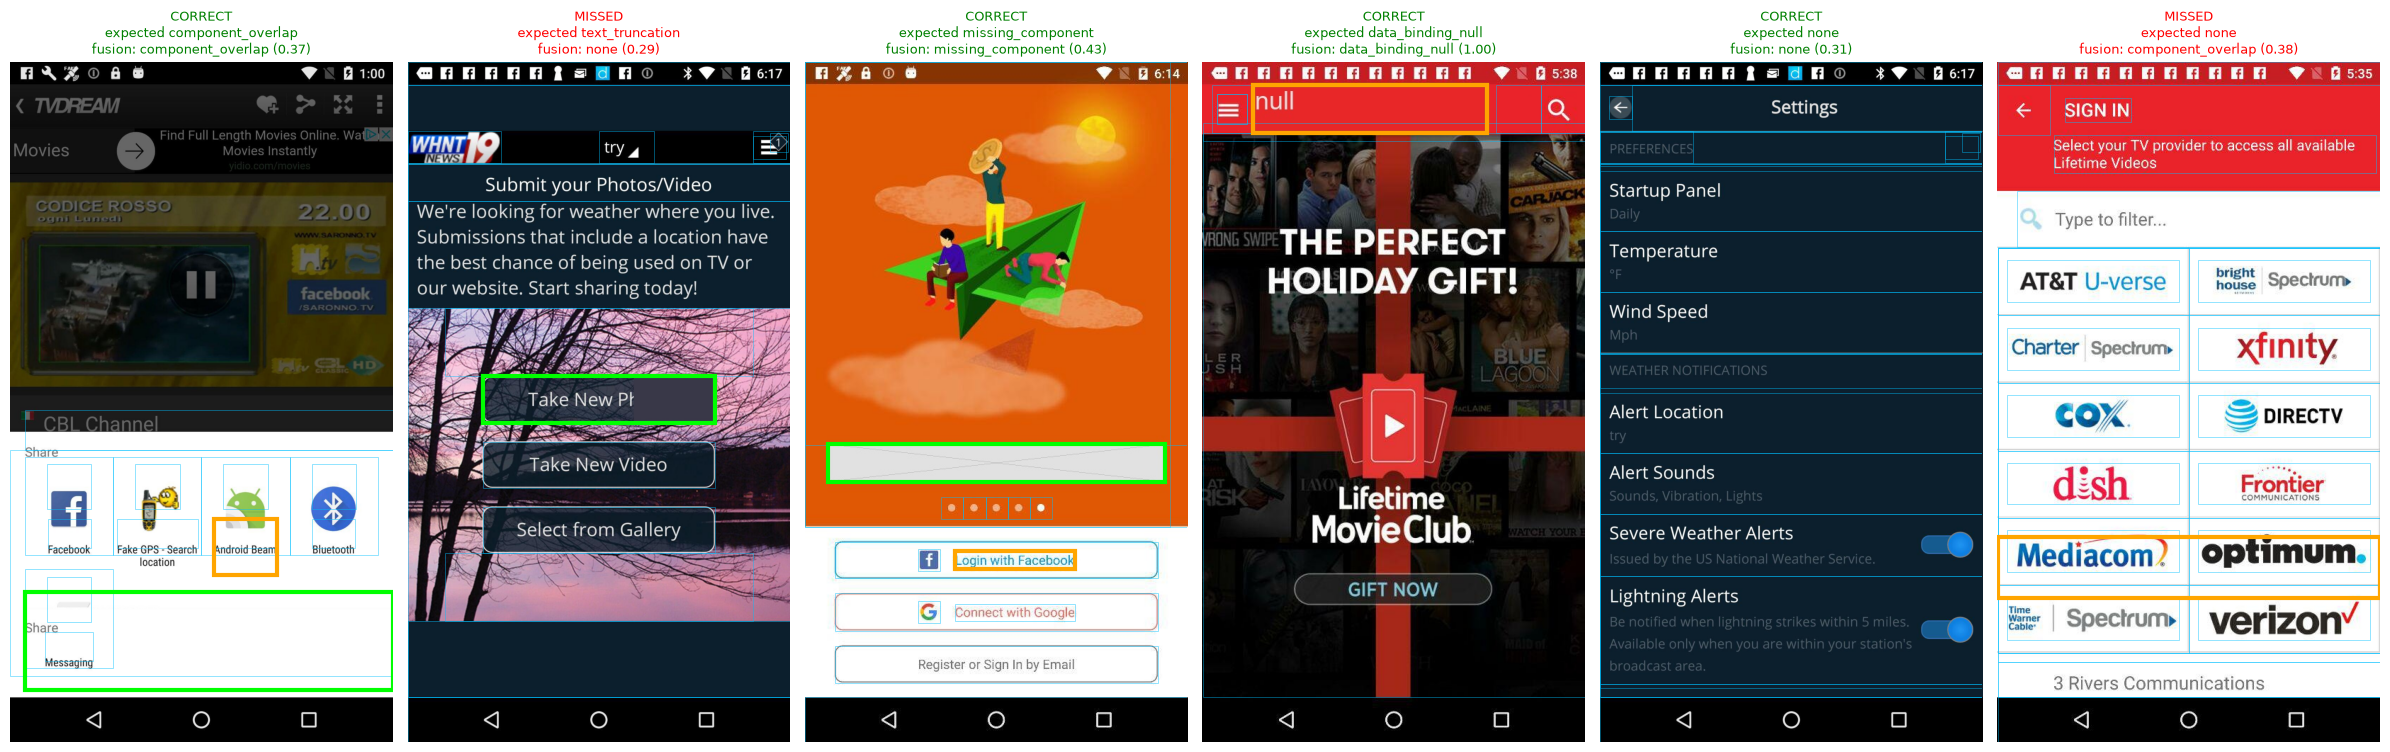

In [7]:
fig, axes = plt.subplots(1, len(SCREENS), figsize=(4 * len(SCREENS), 8))
for ax, s in zip(axes, SCREENS):
    img = Image.open(DIR / s['image']).convert('RGB'); W, H = img.size; ax.imshow(img); ax.axis('off')
    for e in parse_elements(DIR / s['layout']): rect(ax, e.bounds, W, H, 'deepskyblue', lw=0.6, alpha=0.5)
    r = B[s['image']]; rect(ax, s['gold_box'], W, H, 'lime'); rect(ax, r['box'], W, H, 'orange')
    ok = r['type'] == s['expected']
    ax.set_title(f"{'CORRECT' if ok else 'MISSED'}\nexpected {s['expected']}\nfusion: {r['type']} ({r['score']:.2f})", color='green' if ok else 'red', fontsize=9)
plt.tight_layout(); plt.show()

## Side by side

In [8]:
print(f"{'screen':<24}{'expected':<19}{'vision':<20}{'IoU':>5}  {'fusion':<20}{'IoU':>5}")
for s in SCREENS:
    a, b = A[s['image']], B[s['image']]
    print(f"{s['image'][:23]:<24}{s['expected']:<19}{a['type']:<20}{iou(a['box'], s['gold_box']):>5.2f}  {b['type']:<20}{iou(b['box'], s['gold_box']):>5.2f}")
print()
print('vision type correct:', sum(A[s['image']]['type'] == s['expected'] for s in SCREENS), 'of', len(SCREENS))
print('fusion type correct:', sum(B[s['image']]['type'] == s['expected'] for s in SCREENS), 'of', len(SCREENS))
print('Six screens are a demonstration, not an accuracy measure. See C3_v3_measured_results.ipynb for the test-set comparison.')

screen                  expected           vision                IoU  fusion                IoU
10017_v3_overlap.jpg    component_overlap  component_overlap    0.51  component_overlap    0.00
10029_v3_truncation.jpg text_truncation    none                 0.00  none                 0.00
10422_v3_missing.jpg    missing_component  missing_component    0.43  missing_component    0.00
10167_v3_null.jpg       data_binding_null  data_binding_null    0.45  data_binding_null    1.00
10036.jpg               none               none                 0.00  none                 0.00
10182.jpg               none               text_truncation      0.00  component_overlap    0.00

vision type correct: 4 of 6
fusion type correct: 4 of 6
Six screens are a demonstration, not an accuracy measure. See C3_v3_measured_results.ipynb for the test-set comparison.
